In [13]:
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from typing import TypedDict
import time

In [14]:
class CrashState(TypedDict):
    inputt : str
    step1 : str
    step2 : str
    step3 : str

In [15]:
def step1(state: CrashState):
    print("First Step Done")
    return {'step1' : "Done"}

def step2(state: CrashState):
    print("Second Step Started")
    time.sleep(10)
    print("Second Step Done")
    return {'step2' : "Done"}

def step3(state: CrashState):
    print("Third Step Done")
    return {'step3' : "Done"}




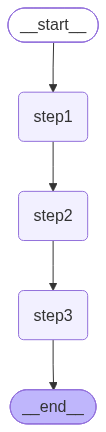

In [16]:
checkpointer = MemorySaver()

builder = StateGraph(CrashState)

builder.add_node('step1', step1)
builder.add_node('step2', step2)
builder.add_node('step3', step3)

builder.add_edge(START, 'step1')
builder.add_edge('step1', 'step2')
builder.add_edge('step2', 'step3')
builder.add_edge('step3', END)

workflow = builder.compile(checkpointer=checkpointer)
workflow

In [17]:
try:
    initial_state = {
        'inputt' : "Hello"
    }

    workflow.invoke(initial_state, config={'configurable' : {'thread_id' : 1}})
except KeyboardInterrupt:
    print("Keyboard interrupted............")

First Step Done
Second Step Started
Keyboard interrupted............


In [18]:
workflow.get_state({'configurable' : {'thread_id' : 1}})

StateSnapshot(values={'inputt': 'Hello', 'step1': 'Done'}, next=('step2',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c997e-65bd-64f7-8001-a1d8ed88dedf'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-10-16T19:29:26.721820+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c997e-65b5-6458-8000-2625bffe86a0'}}, tasks=(PregelTask(id='2c26e737-ed7f-fc44-2c3a-c3dbe8c4e533', name='step2', path=('__pregel_pull', 'step2'), error=None, interrupts=(), state=None, result=None),), interrupts=())

In [19]:
list(workflow.get_state_history({'configurable' : {'thread_id' : 1}}))

[StateSnapshot(values={'inputt': 'Hello', 'step1': 'Done'}, next=('step2',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c997e-65bd-64f7-8001-a1d8ed88dedf'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-10-16T19:29:26.721820+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c997e-65b5-6458-8000-2625bffe86a0'}}, tasks=(PregelTask(id='2c26e737-ed7f-fc44-2c3a-c3dbe8c4e533', name='step2', path=('__pregel_pull', 'step2'), error=None, interrupts=(), state=None, result=None),), interrupts=()),
 StateSnapshot(values={'inputt': 'Hello'}, next=('step1',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c997e-65b5-6458-8000-2625bffe86a0'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-10-16T19:29:26.718530+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c997e-65aa-6

In [20]:
workflow.invoke(None, {'configurable' : {'thread_id' : 1}})
print("Workflow Completed....")

Second Step Started
Second Step Done
Third Step Done
Workflow Completed....


In [21]:
list(workflow.get_state_history({'configurable' : {'thread_id' : 1}}))

[StateSnapshot(values={'inputt': 'Hello', 'step1': 'Done', 'step2': 'Done', 'step3': 'Done'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c9983-7839-6cd7-8003-c8876eaedad7'}}, metadata={'source': 'loop', 'step': 3, 'parents': {}}, created_at='2026-10-16T19:31:42.877987+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c9983-7834-6e5b-8002-f90273017a72'}}, tasks=(), interrupts=()),
 StateSnapshot(values={'inputt': 'Hello', 'step1': 'Done', 'step2': 'Done'}, next=('step3',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c9983-7834-6e5b-8002-f90273017a72'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-10-16T19:31:42.875970+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1c997e-65bd-64f7-8001-a1d8ed88dedf'}}, tasks=(PregelTask(id='39c3aff0-d684-dd60-c4d8-6a0956500245', name='